In [1]:
!pip install kaggle
!pip install opencv-python
!pip install matplotlib
!pip install scikit-image
!pip install torchvision
!pip install tqdm
!pip install h5py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 117.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 102.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitl

In [3]:
from google.colab import files
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
print("Please upload your kaggle.json file:")
uploaded = files.upload()

# Setup Kaggle API
os.environ['KAGGLE_CONFIG_DIR'] = '/content'
!chmod 600 /content/kaggle.json

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json


In [9]:
!kaggle datasets download -d aalniak/kitti-eigen-split-for-monocular-depth-estimation
!unzip -q kitti-eigen-split-for-monocular-depth-estimation.zip -d data


Dataset URL: https://www.kaggle.com/datasets/aalniak/kitti-eigen-split-for-monocular-depth-estimation
License(s): unknown
 97% 799M/824M [00:12<00:00, 285MB/s]
100% 824M/824M [00:12<00:00, 69.7MB/s]


In [10]:
import os, glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


In [21]:
import os
import glob
from sklearn.model_selection import train_test_split

# 1. Get only image_02 camera files
img_files = glob.glob('data/**/**/**/image_02/data/*.png', recursive=True)
depth_files = glob.glob('data/**/**/**/proj_depth/groundtruth/image_02/*.png', recursive=True)

# 2. Index depth files by filename
depth_dict = {os.path.basename(f): f for f in depth_files}

# 3. Match image and depth files by basename
paired_imgs, paired_depths = [], []
for img_path in img_files:
    fname = os.path.basename(img_path)
    if fname in depth_dict:
        paired_imgs.append(img_path)
        paired_depths.append(depth_dict[fname])

print(f"✅ Matched {len(paired_imgs)} image_02 files with ground truth depth")

# 4. Train/Val Split
train_imgs, val_imgs, train_depths, val_depths = train_test_split(
    paired_imgs, paired_depths, test_size=0.2, random_state=42)


✅ Matched 3984 image_02 files with ground truth depth


In [31]:
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

transform = transforms.Compose([
    transforms.Resize((256, 512)),
])

class KITTI_Dataset(Dataset):
    def __init__(self, image_paths, depth_paths, transform=None):
        self.imgs = image_paths
        self.depths = depth_paths
        self.transform = transform

    def __len__(self): return len(self.imgs)

    def __getitem__(self, idx):
        img = Image.open(self.imgs[idx]).convert('RGB')
        depth = Image.open(self.depths[idx])

        if self.transform:
            img = self.transform(img)
            depth = self.transform(depth)

        img = transforms.ToTensor()(img)
        depth = transforms.ToTensor()(depth).float() # Convert depth to float

        return img, depth


train_ds = KITTI_Dataset(train_imgs, train_depths, transform)
val_ds = KITTI_Dataset(val_imgs, val_depths, transform)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=8, shuffle=False)

In [23]:
class UNetBasic(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(3,64,3,padding=1), nn.ReLU(), nn.Conv2d(64,64,3,padding=1), nn.ReLU())
        self.pool = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.Conv2d(128,128,3,padding=1), nn.ReLU())
        self.dec2 = nn.Sequential(nn.Conv2d(128,64,3,padding=1), nn.ReLU())
        self.dec1 = nn.Sequential(nn.Conv2d(128,64,3,padding=1), nn.ReLU(), nn.Conv2d(64,1,1))
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        d2 = self.up(self.dec2(e2))
        d1 = self.dec1(torch.cat([d2, e1], dim=1))
        return d1

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNetBasic().to(device)


In [24]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


In [33]:
def train_epoch(model, loader):
    model.train()
    total_loss = 0
    for imgs, depths in loader:
        imgs, depths = imgs.to(device), depths.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, depths)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)

def eval_epoch(model, loader):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for imgs, depths in loader:
            imgs, depths = imgs.to(device), depths.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, depths)
            total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)


In [35]:
epochs = 5
for e in range(epochs):
    train_loss = train_epoch(model, train_loader)
    val_loss = eval_epoch(model, val_loader)
    print(f"Epoch {e+1}/{epochs}: Train MSE={train_loss:.4f}, Val MSE={val_loss:.4f}")


Epoch 1/5: Train MSE=1884299.1975, Val MSE=1860941.0154
Epoch 2/5: Train MSE=1880627.9144, Val MSE=1846348.0525
Epoch 3/5: Train MSE=1870745.4426, Val MSE=1862811.9476
Epoch 4/5: Train MSE=1864705.2824, Val MSE=1836735.0529
Epoch 5/5: Train MSE=1859686.9393, Val MSE=1827723.0778


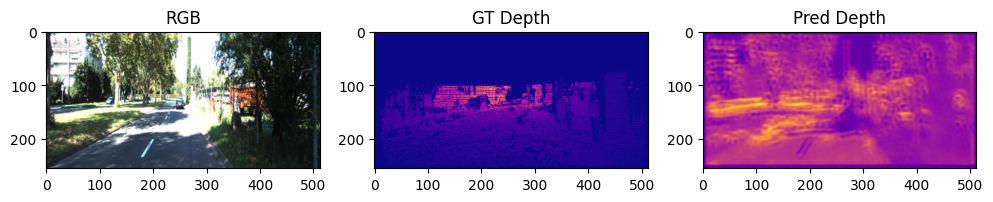

In [39]:
model.eval()
imgs, depths = next(iter(val_loader))
imgs = imgs.to(device)
preds = model(imgs).cpu().detach() # Move preds to CPU

def display(idx):
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.title('RGB'); plt.imshow(imgs[idx].cpu().permute(1,2,0)) # Move imgs to CPU
    plt.subplot(1,3,2); plt.title('GT Depth'); plt.imshow(depths[idx][0], cmap='plasma')
    plt.subplot(1,3,3); plt.title('Pred Depth'); plt.imshow(preds[idx][0], cmap='plasma')
    plt.show()

display(0)

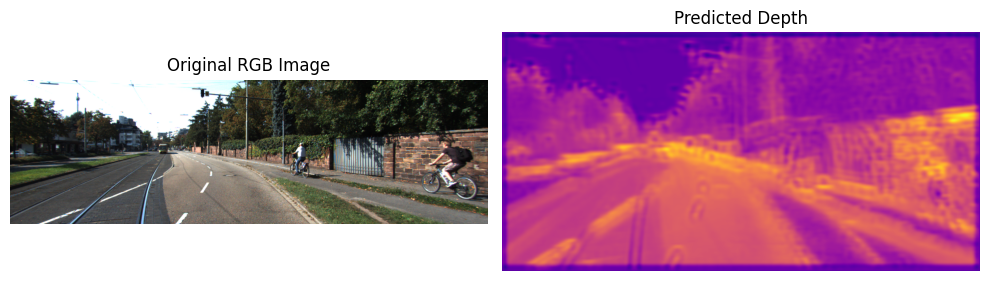

In [49]:
def predict_depth(img_path, model):
    model.eval()
    img = Image.open(img_path).convert('RGB')
    img_t = transform(img) # Apply resize transform
    img_t = transforms.ToTensor()(img_t).unsqueeze(0).to(device) # Convert to tensor and add batch dimension
    with torch.no_grad():
        pred = model(img_t).cpu().squeeze(0)[0]
    return pred.unsqueeze(0), img # Return original image as well

# Example:
img_path = '/content/data/2011_09_26/2011_09_26_drive_0002_sync/image_02/data/0000000006.png'
predicted_depth_map, original_img = predict_depth(img_path, model) # Get original image

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('Original RGB Image')
plt.imshow(original_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Predicted Depth')
plt.imshow(predicted_depth_map[0], cmap='plasma')
plt.axis('off')

plt.tight_layout()
plt.show()

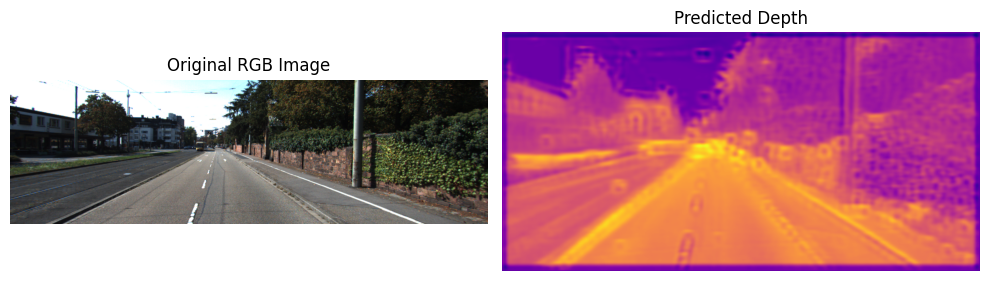

In [50]:
img_path = '/content/data/2011_09_26/2011_09_26_drive_0002_sync/image_02/data/0000000030.png'
predicted_depth_map, original_img = predict_depth(img_path, model) # Get original image

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('Original RGB Image')
plt.imshow(original_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Predicted Depth')
plt.imshow(predicted_depth_map[0], cmap='plasma')
plt.axis('off')

plt.tight_layout()
plt.show()

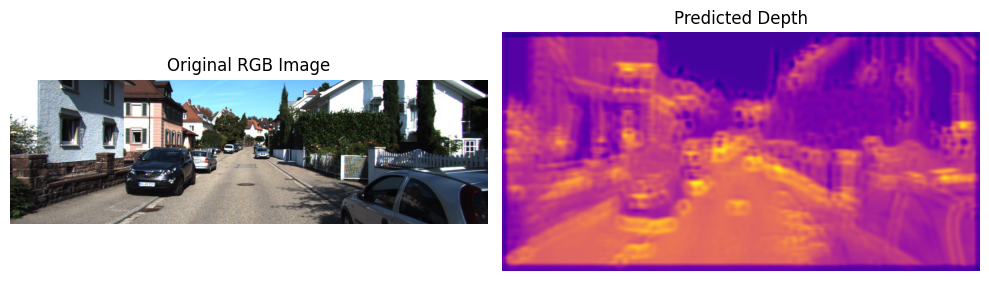

In [51]:
img_path = '/content/data/2011_09_26/2011_09_26_drive_0064_sync/image_02/data/0000000066.jpg'
predicted_depth_map, original_img = predict_depth(img_path, model) # Get original image

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('Original RGB Image')
plt.imshow(original_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Predicted Depth')
plt.imshow(predicted_depth_map[0], cmap='plasma')
plt.axis('off')

plt.tight_layout()
plt.show()

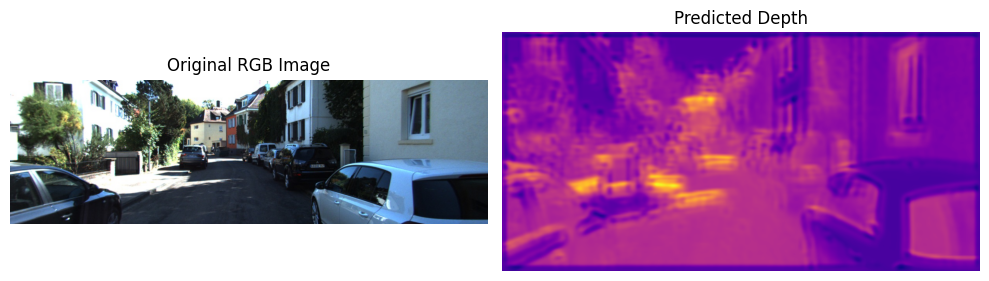

In [52]:
img_path = '/content/data/2011_09_30/2011_09_30_drive_0027_sync/image_03/data/0000000205.jpg'
predicted_depth_map, original_img = predict_depth(img_path, model) # Get original image

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('Original RGB Image')
plt.imshow(original_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Predicted Depth')
plt.imshow(predicted_depth_map[0], cmap='plasma')
plt.axis('off')

plt.tight_layout()
plt.show()

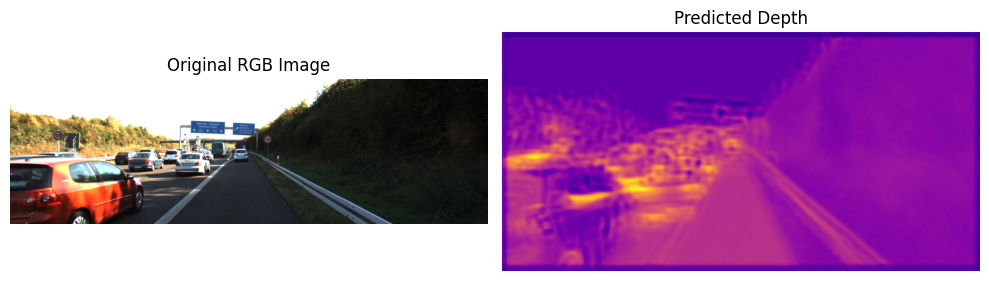

In [53]:
img_path = '/content/data/2011_10_03/2011_10_03_drive_0047_sync/image_02/data/0000000416.png'
predicted_depth_map, original_img = predict_depth(img_path, model) # Get original image

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title('Original RGB Image')
plt.imshow(original_img)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Predicted Depth')
plt.imshow(predicted_depth_map[0], cmap='plasma')
plt.axis('off')

plt.tight_layout()
plt.show()